# Семинар 2. Нормализующие потоки и диффузионные модели

**Газпром · 90 минут · практикум с готовым кодом**

- **Подготовка:** Python, основы нейросетей.
- **Цель:** оценивание плотности, генерация и редактирование изображений.
- **Данные:** двумерные точки; рукописные цифры 8×8 из scikit-learn.
- **Формат:** выполнение ячеек, анализ графиков, изменение параметров.
- **Запуск:** загрузить notebook в [Colab](https://colab.research.google.com/) → «Выполнить все». CPU достаточно; GPU необязателен. Данные доступны без скачивания.
- **Область применимости:** учебные эксперименты; качество на фотографиях и производственных данных не оценивается.

| Минуты | Основной материал |
|---|---|
| 0–8 | Связь с VAE/GAN; гауссовская модель |
| 8–30 | RealNVP: преобразования, плотность, обратимость |
| 30–60 | DDPM: зашумление, обучение, генерация |
| 60–80 | Image-to-image: эксперимент с уровнем шума |
| 80–90 | Сравнение моделей; контрольные вопросы |

Дополнительно: число слоёв потока, якобиан, коэффициенты posterior, inpainting.
«Выполнить все» выполняет также дополнительные ячейки.

## 0. Среда и воспроизводимость

- Фиксированы seed и два CPU-потока; версии выводятся ниже.
- Побитовое совпадение разных GPU и версий не гарантируется.
- Отсутствующие библиотеки устанавливаются автоматически.

In [1]:
import importlib.util
import os
import subprocess
import sys

packages = {"torch": "torch", "numpy": "numpy", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import math
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.datasets import load_digits, make_moons
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUICK = os.environ.get("SEMINAR_QUICK", "0") == "1"
plt.rcParams.update({"figure.figsize": (9, 3), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "NumPy:", np.__version__, "scikit-learn:", sklearn.__version__)
print("Device:", device, "Quick smoke mode:", QUICK)

Python: 3.12.7
PyTorch: 2.14.1 NumPy: 2.5.4 scikit-learn: 1.9.1
Device: cpu Quick smoke mode: False


## 1. Оценивание двумерного распределения

- **Данные:** точки $x=(x_1,x_2)$; две зашумлённые полуокружности.
- **Базовая модель:** нормальное распределение с полной ковариационной матрицей.
- **Разбиение:** train/test до стандартизации; параметры стандартизации вычисляются по train.
- **Критерий:** отрицательное логарифмическое правдоподобие (NLL) на test.

Теория: [Генеративное моделирование](https://fpakhurov.com/ru/notes/generative-models/generative-modeling/).

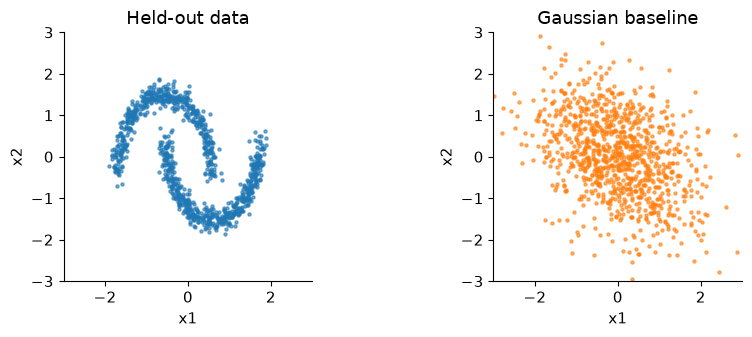

Gaussian held-out NLL: 2.7190 nats per 2D point


In [2]:
moons, moon_labels = make_moons(n_samples=5000, noise=0.07, random_state=SEED)
moon_train_np, moon_test_np = train_test_split(moons, test_size=0.2, random_state=SEED)
moon_mean = moon_train_np.mean(axis=0)
moon_scale = moon_train_np.std(axis=0)
moon_train = torch.tensor((moon_train_np - moon_mean) / moon_scale, dtype=torch.float32, device=device)
moon_test = torch.tensor((moon_test_np - moon_mean) / moon_scale, dtype=torch.float32, device=device)
gaussian_mean = moon_train.mean(dim=0)
centered = moon_train - gaussian_mean
gaussian_cov = centered.T @ centered / len(moon_train) + 1e-5 * torch.eye(2, device=device)
gaussian = torch.distributions.MultivariateNormal(gaussian_mean, covariance_matrix=gaussian_cov)
gaussian_nll = -gaussian.log_prob(moon_test).mean().item()
gaussian_samples = gaussian.sample((1000,)).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].scatter(*moon_test.cpu().numpy().T, s=5, alpha=0.6)
axes[1].scatter(*gaussian_samples.T, s=5, alpha=0.6, color="tab:orange")
for ax, title in zip(axes, ["Held-out data", "Gaussian baseline"]):
    ax.set(title=title, xlim=(-3, 3), ylim=(-3, 3), aspect="equal", xlabel="x1", ylabel="x2")
plt.tight_layout()
plt.show()
print(f"Gaussian held-out NLL: {gaussian_nll:.4f} nats per 2D point")

- **Ограничение базовой модели:** одна нормаль не воспроизводит изогнутую форму распределения.
- **Нормализующий поток:** обратимое преобразование $z=f_\theta(x)$ к $\mathcal N(0,I)$.
- **Генерация:** $z\sim\mathcal N(0,I)$, затем $x=f_\theta^{-1}(z)$.
- **Размерность:** $x,z\in\mathbb R^2$; сжатия размерности нет.

Теория: [Нормализующие потоки](https://fpakhurov.com/ru/notes/generative-models/normalizing-flows/).

## 2. Замена переменных и архитектура RealNVP

<img src="https://lilianweng.github.io/posts/2018-10-13-flow-models/normalizing-flow.png" alt="Normalizing flow: composition of invertible transformations" width="720">

*Композиция обратимых преобразований. [Lilian Weng (2018)](https://lilianweng.github.io/posts/2018-10-13-flow-models/). На схеме: шум → данные; в коде `forward`: данные → код.*

**Плотность; направление данные → код:**

$$\log p_\theta(x)=\log p_Z(f_\theta(x))+
\log\left|\det\frac{\partial f_\theta(x)}{\partial x}\right|.$$

- $p_Z$ — стандартная нормальная плотность; $\theta$ — параметры сети.
- $|\det J_f|$ — локальное изменение объёма; `logdet` — его логарифм.
- **Цель:** $\displaystyle\min_\theta-\frac1N\sum_{i=1}^N\log p_\theta(x_i)$; $N$ — число объектов.
- NLL измеряется в натах на двумерную точку. Непрерывная плотность может превышать 1; NLL может быть отрицательной.

**Affine coupling:**

$$z_1=x_1,\qquad z_2=x_2e^{s_\theta(x_1)}+b_\theta(x_1).$$
$$x_1=z_1,\qquad x_2=(z_2-b_\theta(z_1))e^{-s_\theta(z_1)}.$$

- $s_\theta,b_\theta$ — нейросети масштаба и сдвига; их обратимость не требуется.
- Якобиан треугольный: $\log|\det J|=s_\theta(x_1)$.
- Чередование масок изменяет обе координаты; `mask=1` сохраняет координату.

Теория: [Замена переменных](https://fpakhurov.com/ru/notes/generative-models/normalizing-flows/#change-of-variables), [coupling NICE/RealNVP](https://fpakhurov.com/ru/notes/generative-models/flow-architectures/#a-coupling-layers-nice-realnvp).

In [3]:
class AffineCoupling(nn.Module):
    def __init__(self, mask, width=64):
        super().__init__()
        self.register_buffer("mask", torch.tensor(mask, dtype=torch.float32))
        self.net = nn.Sequential(nn.Linear(2, width), nn.Tanh(), nn.Linear(width, width), nn.Tanh(), nn.Linear(width, 4))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def scale_shift(self, fixed):
        raw_scale, shift = self.net(fixed).chunk(2, dim=-1)
        scale = 0.8 * torch.tanh(raw_scale) * (1 - self.mask)
        shift = shift * (1 - self.mask)
        return scale, shift

    def forward(self, x):
        fixed = x * self.mask
        scale, shift = self.scale_shift(fixed)
        z = fixed + (1 - self.mask) * (x * scale.exp() + shift)
        return z, scale.sum(dim=-1)

    def inverse(self, z):
        fixed = z * self.mask
        scale, shift = self.scale_shift(fixed)
        x = fixed + (1 - self.mask) * ((z - shift) * (-scale).exp())
        return x, -scale.sum(dim=-1)


class RealNVP(nn.Module):
    def __init__(self, n_layers=8):
        super().__init__()
        self.layers = nn.ModuleList([AffineCoupling([i % 2, 1 - i % 2]) for i in range(n_layers)])

    def forward(self, x):
        logdet = x.new_zeros(len(x))
        for layer in self.layers:
            x, increment = layer(x)
            logdet = logdet + increment
        return x, logdet

    def inverse(self, z, return_stages=False):
        stages = [z.detach().cpu().numpy()]
        logdet = z.new_zeros(len(z))
        for layer in reversed(self.layers):
            z, increment = layer.inverse(z)
            logdet = logdet + increment
            if return_stages:
                stages.append(z.detach().cpu().numpy())
        return (z, logdet, stages) if return_stages else (z, logdet)

    def log_prob(self, x):
        z, logdet = self(x)
        log_base = -0.5 * (z.square() + math.log(2 * math.pi)).sum(dim=-1)
        return log_base + logdet


flow = RealNVP(n_layers=8).to(device)
print("Input: [batch, 2]; code: [batch, 2]; logdet: [batch]")

Input: [batch, 2]; code: [batch, 2]; logdet: [batch]


## 3. Обучение и проверка потока

- **Оптимизация:** случайные train-батчи; минимизация NLL.
- **Оценивание:** test NLL относительно гауссовской модели; test исключён из градиентов.
- **Визуализация:** коды test-объектов и генерация из нормального распределения.

Flow training and evaluation: 5.5 seconds
Held-out NLL, Gaussian: 2.7190; flow: 1.5948 nats per 2D point
Flow NLL improvement: 1.1242


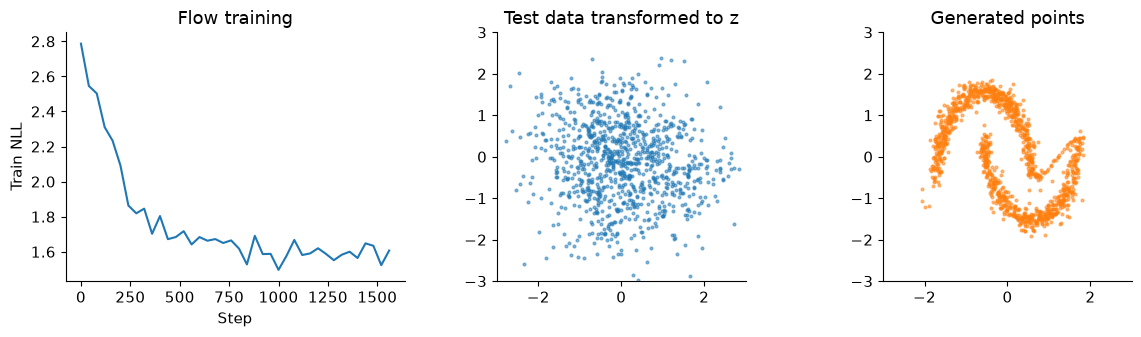

In [4]:
FLOW_STEPS = 120 if QUICK else 1600
flow_optimizer = torch.optim.Adam(flow.parameters(), lr=1e-3)
flow_history = []
flow_start = time.perf_counter()
for step in range(FLOW_STEPS):
    indices = torch.randint(len(moon_train), (256,), device=device)
    flow_loss = -flow.log_prob(moon_train[indices]).mean()
    flow_optimizer.zero_grad(set_to_none=True)
    flow_loss.backward()
    torch.nn.utils.clip_grad_norm_(flow.parameters(), 5.0)
    flow_optimizer.step()
    if step % 40 == 0:
        flow_history.append((step, flow_loss.item()))
flow.eval()
with torch.no_grad():
    flow_nll = -flow.log_prob(moon_test).mean().item()
    latent_test, _ = flow(moon_test)
    base = torch.randn(1200, 2, device=device)
    flow_samples, _, flow_stages = flow.inverse(base, return_stages=True)
flow_seconds = time.perf_counter() - flow_start
print(f"Flow training and evaluation: {flow_seconds:.1f} seconds")
print(f"Held-out NLL, Gaussian: {gaussian_nll:.4f}; flow: {flow_nll:.4f} nats per 2D point")
print("Flow NLL improvement:", round(gaussian_nll - flow_nll, 4))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].plot(*np.array(flow_history).T)
axes[0].set(title="Flow training", xlabel="Step", ylabel="Train NLL")
axes[1].scatter(*latent_test.cpu().numpy().T, s=4, alpha=0.5)
axes[1].set(title="Test data transformed to z", xlim=(-3, 3), ylim=(-3, 3), aspect="equal")
axes[2].scatter(*flow_samples.cpu().numpy().T, s=4, alpha=0.5, color="tab:orange")
axes[2].set(title="Generated points", xlim=(-3, 3), ylim=(-3, 3), aspect="equal")
plt.tight_layout()
plt.show()

- **Обратимость:** проверка `inverse(forward(x)) ≈ x`.
- **Дополнительно:** сравнение аналитического logdet с полным якобианом autograd.
- **Визуализация:** одинаковый цвет соответствует одним точкам на последовательных стадиях преобразования.

Roundtrip max error: 7.15e-07
Forward/inverse logdet cancellation: 4.77e-07
Autograd/analytic logdet error: 1.67e-06


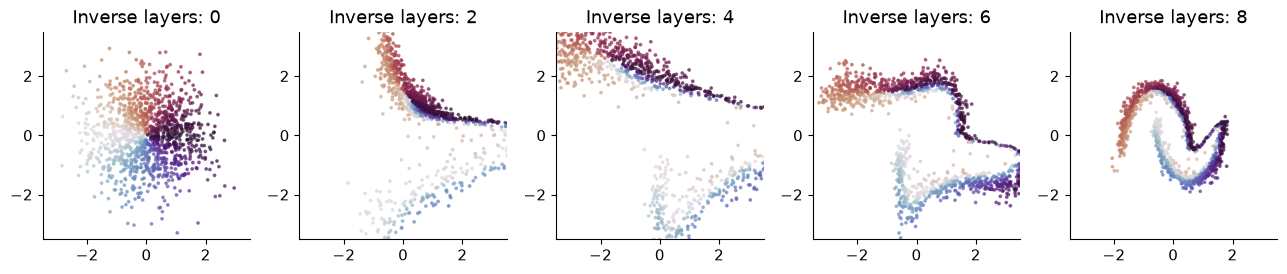

In [5]:
with torch.no_grad():
    probe = moon_test[:32]
    probe_z, forward_logdet = flow(probe)
    recovered, inverse_logdet = flow.inverse(probe_z)
    roundtrip_error = (recovered - probe).abs().max().item()
    logdet_cancellation = (forward_logdet + inverse_logdet).abs().max().item()
assert roundtrip_error < 2e-4, roundtrip_error
assert logdet_cancellation < 2e-4, logdet_cancellation

point = moon_test[0].detach().clone().requires_grad_(True)
jacobian = torch.autograd.functional.jacobian(lambda v: flow(v.unsqueeze(0))[0].squeeze(0), point)
autograd_logdet = torch.linalg.slogdet(jacobian)[1]
analytic_logdet = flow(point.unsqueeze(0))[1][0]
jacobian_logdet_error = (autograd_logdet - analytic_logdet).abs().item()
assert jacobian_logdet_error < 2e-4, jacobian_logdet_error
print(f"Roundtrip max error: {roundtrip_error:.2e}")
print(f"Forward/inverse logdet cancellation: {logdet_cancellation:.2e}")
print(f"Autograd/analytic logdet error: {jacobian_logdet_error:.2e}")

fig, axes = plt.subplots(1, 5, figsize=(13, 3))
colors = np.arctan2(flow_stages[0][:, 1], flow_stages[0][:, 0])
for ax, stage in zip(axes, [0, 2, 4, 6, 8]):
    ax.scatter(*flow_stages[stage].T, c=colors, cmap="twilight", s=3, alpha=0.6)
    ax.set(title=f"Inverse layers: {stage}", xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), aspect="equal")
plt.tight_layout()
plt.show()

- **Ограничения:** специальная обратимая архитектура; положительная плотность при нормальном prior. Данные имеют ненулевой шум.
- **Дополнительный эксперимент:** 8 → 2 слоя; сравнить test NLL и генерацию. Для графика стадий задать `[0, 1, 2]` и три оси.

<details><summary>Пояснение</summary>

Один coupling-слой сохраняет часть координат. Чередование масок обеспечивает преобразование обеих. Дополнительные слои повышают выразительность, но не гарантируют улучшение test NLL.
</details>

Теория: [Архитектуры потоков](https://fpakhurov.com/ru/notes/generative-models/flow-architectures/).

## 4. DDPM: прямой процесс

<img src="https://hojonathanho.github.io/diffusion/assets/img/pgm_diagram_xarrow.png" alt="DDPM: forward noising and learned reverse Markov chains" width="720">

*Прямой и обратный процессы DDPM. [Ho, Jain, Abbeel (2020)](https://hojonathanho.github.io/diffusion/).*

- **Данные:** $x_0\in[-1,1]^{64}$ — развёрнутое изображение 8×8.
- **Переход:** $q(x_k\mid x_{k-1})=\mathcal N(\sqrt{\alpha_k}x_{k-1},\beta_k I)$.
- $k=1,\ldots,T$ — шаг; $\beta_k$ — дисперсия шума; $\alpha_k=1-\beta_k$.
- $\bar\alpha_k=\prod_{j=1}^k\alpha_j$, $\bar\alpha_0=1$.

**Прямое получение зашумлённого примера:**

$$x_k=\sqrt{\bar\alpha_k}x_0+\sqrt{1-\bar\alpha_k}\,\varepsilon,
\qquad\varepsilon\sim\mathcal N(0,I).$$

- Чистый объект и добавленный шум известны при обучении.
- **Индексы Python:** `t=k-1`; `q_sample(x0, t=0)` соответствует первому зашумлению.

Теория: [Прямой переход к произвольному шагу](https://fpakhurov.com/ru/notes/generative-models/ddpm-forward-process/#the-jump-from-x-to-any-step).

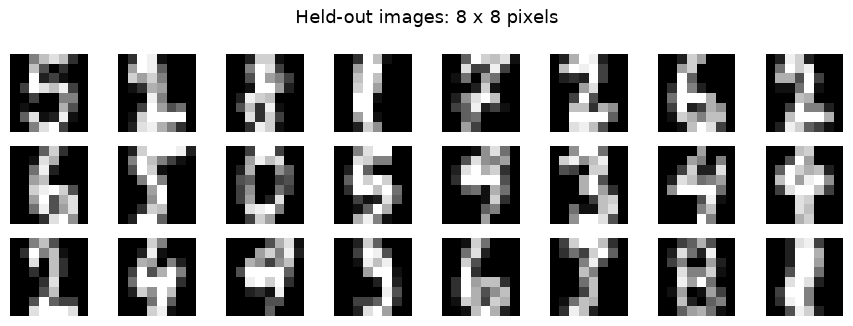

Train: (1437, 64) Test: (360, 64)


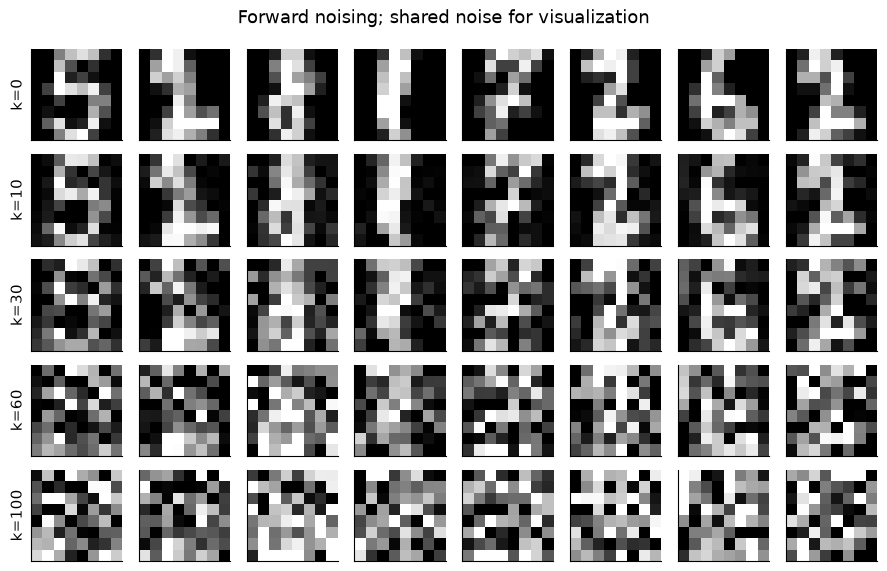

Terminal alpha_bar: 2.43e-07


In [6]:
digits = load_digits()
digit_train_np, digit_test_np = train_test_split(digits.data / 16.0, test_size=0.2, random_state=SEED, stratify=digits.target)
x_train = torch.tensor(digit_train_np * 2 - 1, dtype=torch.float32, device=device)
x_test = torch.tensor(digit_test_np * 2 - 1, dtype=torch.float32, device=device)

def image_grid(images, title, cols=8, value_range=(-1, 1)):
    images = images.detach().cpu().numpy() if torch.is_tensor(images) else np.asarray(images)
    images = images.reshape(-1, 8, 8)
    rows = math.ceil(len(images) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.1, rows * 1.1), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image in zip(axes.flat, images):
        ax.imshow(image, cmap="gray", vmin=value_range[0], vmax=value_range[1], interpolation="nearest")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

image_grid(x_test[:24], "Held-out images: 8 x 8 pixels")
print("Train:", tuple(x_train.shape), "Test:", tuple(x_test.shape))

T = 100
grid = torch.linspace(0, T, T + 1, device=device)
cosine = torch.cos(((grid / T + 0.008) / 1.008) * math.pi / 2).square()
cosine = cosine / cosine[0]
betas = (1 - cosine[1:] / cosine[:-1]).clamp(1e-5, 0.999)
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_previous = torch.cat([torch.ones(1, device=device), alpha_bars[:-1]])
posterior_variance = betas * (1 - alpha_bars_previous) / (1 - alpha_bars)
posterior_coef_x0 = betas * alpha_bars_previous.sqrt() / (1 - alpha_bars)
posterior_coef_xt = alphas.sqrt() * (1 - alpha_bars_previous) / (1 - alpha_bars)

def extract(values, t):
    return values[t].unsqueeze(-1)

def q_sample(x0, t, noise=None):
    noise = torch.randn_like(x0) if noise is None else noise
    return extract(alpha_bars.sqrt(), t) * x0 + extract((1 - alpha_bars).sqrt(), t) * noise

fixed_noise = torch.randn_like(x_test[:8])
fig, axes = plt.subplots(5, 8, figsize=(9, 5.8))
for row, k in enumerate([0, 10, 30, 60, 100]):
    if k == 0:
        corrupted = x_test[:8]
    else:
        corrupted = q_sample(x_test[:8], torch.full((8,), k - 1, dtype=torch.long, device=device), fixed_noise)
    for col, ax in enumerate(axes[row]):
        ax.imshow(corrupted[col].detach().cpu().reshape(8, 8), cmap="gray", vmin=-1, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(f"k={k}")
fig.suptitle("Forward noising; shared noise for visualization")
plt.tight_layout()
plt.show()
print(f"Terminal alpha_bar: {alpha_bars[-1].item():.2e}")

- Показаны маргинальные распределения $q(x_k\mid x_0)$ с общим шумом для визуального сравнения.
- Это не одна марковская траектория.
- При малом $\bar\alpha_T$ распределение $x_T$ приближается к $\mathcal N(0,I)$.

## 5. Предсказание шума: архитектура и функция потерь

<img src="https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/u-net-architecture.png" alt="Original U-Net: contracting and expanding paths with skip connections" width="720">

*Исходная U-Net для сегментации: [Ronneberger et al. (2015)](https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/). В DDPM используют модификации с кодированием времени; в практикуме — MLP.*

- **Архитектура:** MLP; синусоидальное кодирование времени.
- **Вход:** `x_t: [batch, 64]`, `t: [batch]`; **выход:** `eps_pred: [batch, 64]`.
- **Цель DDPM:**

$$\min_\theta\;\mathbb E_{x_0,k,\varepsilon}
\left[\frac1{64}\|\varepsilon-\varepsilon_\theta(x_k,k)\|_2^2\right].$$

- $k$ выбирается равномерно; $\varepsilon_\theta$ — предсказание шума сетью.
- Невзвешенный MSE связан с вариационным обучением, но численно не равен NLL или ELBO.
- Для крупных изображений применяются более выразительные архитектуры, включая U-Net.

Теория: [Предсказание шума](https://fpakhurov.com/ru/notes/generative-models/ddpm-training-objective/#from-means-to-noise), [Score matching](https://fpakhurov.com/ru/notes/generative-models/score-matching/).

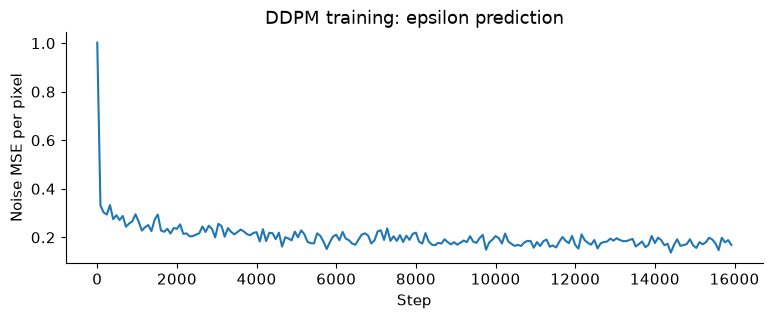

DDPM training: 24.3 seconds
Held-out noise MSE: 0.2070; zero predictor baseline: 0.9933


In [7]:
class EpsilonMLP(nn.Module):
    def __init__(self, width=256, time_dim=64):
        super().__init__()
        self.register_buffer("frequencies", torch.exp(torch.linspace(math.log(1.0), math.log(1000.0), time_dim // 2)))
        self.input_layer = nn.Linear(64 + time_dim, width)
        self.hidden1 = nn.Linear(width, width)
        self.hidden2 = nn.Linear(width, width)
        self.output_layer = nn.Linear(width, 64)

    def forward(self, x_t, t):
        angles = (t.float() / (T - 1)).unsqueeze(-1) * self.frequencies
        embedding = torch.cat([angles.sin(), angles.cos()], dim=-1)
        h = F.silu(self.input_layer(torch.cat([x_t, embedding], dim=-1)))
        h = h + F.silu(self.hidden1(h))
        h = h + F.silu(self.hidden2(h))
        return self.output_layer(h)

denoiser = EpsilonMLP().to(device)
diffusion_optimizer = torch.optim.AdamW(denoiser.parameters(), lr=1e-3, weight_decay=1e-4)
DDPM_STEPS = 120 if QUICK else 16000
ddpm_history = []
ddpm_start = time.perf_counter()
denoiser.train()
for step in range(DDPM_STEPS):
    indices = torch.randint(len(x_train), (128,), device=device)
    x0_batch = x_train[indices]
    t_batch = torch.randint(T, (len(x0_batch),), device=device)
    noise = torch.randn_like(x0_batch)
    x_t = q_sample(x0_batch, t_batch, noise)
    eps_pred = denoiser(x_t, t_batch)
    loss = F.mse_loss(eps_pred, noise)
    diffusion_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(denoiser.parameters(), 1.0)
    diffusion_optimizer.step()
    if step % 80 == 0:
        ddpm_history.append((step, loss.item()))
denoiser.eval()
ddpm_seconds = time.perf_counter() - ddpm_start
with torch.no_grad():
    eval_t = torch.randint(T, (len(x_test),), device=device)
    eval_noise = torch.randn_like(x_test)
    eval_xt = q_sample(x_test, eval_t, eval_noise)
    test_noise_mse = F.mse_loss(denoiser(eval_xt, eval_t), eval_noise).item()
    zero_noise_mse = eval_noise.square().mean().item()
plt.plot(*np.array(ddpm_history).T)
plt.title("DDPM training: epsilon prediction")
plt.xlabel("Step")
plt.ylabel("Noise MSE per pixel")
plt.show()
print(f"DDPM training: {ddpm_seconds:.1f} seconds")
print(f"Held-out noise MSE: {test_noise_mse:.4f}; zero predictor baseline: {zero_noise_mse:.4f}")

- **Диагностика:** test MSE отдельно для нескольких уровней шума.
- Низкий MSE предсказания шума не гарантирует точное восстановление оригинала, качество или разнообразие генерации.

In [8]:
noise_mse_by_step = {}
with torch.no_grad():
    for k in [1, 10, 30, 60, 90, 100]:
        level_t = torch.full((len(x_test),), k - 1, dtype=torch.long, device=device)
        level_noise = torch.randn_like(x_test)
        level_xt = q_sample(x_test, level_t, level_noise)
        noise_mse_by_step[k] = F.mse_loss(denoiser(level_xt, level_t), level_noise).item()
print("Held-out noise MSE by k:", {k: round(v, 4) for k, v in noise_mse_by_step.items()})

Held-out noise MSE by k: {1: 0.953, 10: 0.4956, 30: 0.2162, 60: 0.0936, 90: 0.0182, 100: 0.0129}


## 6. Обратный процесс и апостериорное распределение

**При известных $x_0,x_k$:**

$$q(x_{k-1}\mid x_k,x_0)=\mathcal N(\tilde\mu_k,\tilde\beta_k I).$$

<details><summary>Дополнительно: точные коэффициенты posterior</summary>

$$\tilde\mu_k=
\frac{\sqrt{\bar\alpha_{k-1}}\beta_k}{1-\bar\alpha_k}x_0+
\frac{\sqrt{\alpha_k}(1-\bar\alpha_{k-1})}{1-\bar\alpha_k}x_k,$$
$$\tilde\beta_k=\beta_k\frac{1-\bar\alpha_{k-1}}{1-\bar\alpha_k}.$$

Коэффициенты получаются из произведения гауссовских плотностей прямого процесса.
</details>

**При генерации:** оригинал неизвестен; используется оценка

$$\hat x_0=\frac{x_k-\sqrt{1-\bar\alpha_k}\,\varepsilon_\theta(x_k,k)}{\sqrt{\bar\alpha_k}}.$$

- Среднее $p_\theta(x_{k-1}\mid x_k)$ использует $\hat x_0$; дисперсия фиксирована: $\tilde\beta_k$.
- `clamp(-1, 1)` ограничивает оценку диапазоном данных.
- При $k=1$ дисперсия равна нулю; дополнительный шум отсутствует.
- Обученный переход приближённый; он не совпадает с точным posterior по одному $x_k$.

Теория: [Истинный posterior](https://fpakhurov.com/ru/notes/generative-models/ddpm-training-objective/#the-true-posterior), [обратная цепочка](https://fpakhurov.com/ru/notes/generative-models/ddpm-training-objective/#sampling-running-the-chain-backwards).

Known-noise x0 reconstruction error: 1.15e-04


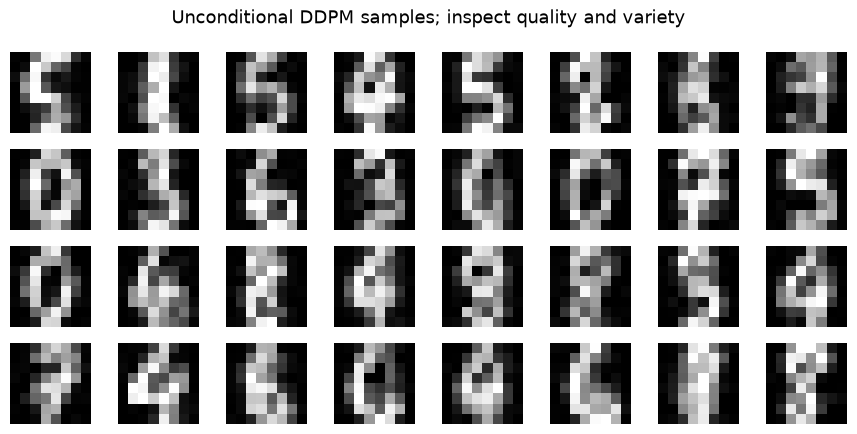

In [9]:
def x0_from_epsilon(x_t, t, epsilon):
    return (x_t - extract((1 - alpha_bars).sqrt(), t) * epsilon) / extract(alpha_bars.sqrt(), t)


@torch.no_grad()
def reverse_step(x_t, t):
    eps_pred = denoiser(x_t, t)
    x0_pred = x0_from_epsilon(x_t, t, eps_pred).clamp(-1, 1)
    mean = extract(posterior_coef_x0, t) * x0_pred + extract(posterior_coef_xt, t) * x_t
    noise = torch.randn_like(x_t)
    nonzero = (t > 0).float().unsqueeze(-1)
    return mean + nonzero * extract(posterior_variance.clamp(min=0).sqrt(), t) * noise


@torch.no_grad()
def sample_ddpm(count=32, initial=None, start_t=None, snapshots=False):
    denoiser.eval()
    current = torch.randn(count, 64, device=device) if initial is None else initial.clone()
    start_t = T - 1 if start_t is None else start_t
    trace = {start_t + 1: current.detach().clone()}
    for step_t in range(start_t, -1, -1):
        t = torch.full((len(current),), step_t, dtype=torch.long, device=device)
        current = reverse_step(current, t)
        if snapshots and step_t in [75, 50, 25, 10, 0]:
            trace[step_t] = current.detach().clone()
    return current, trace


probe_t = torch.tensor([0, 10, 99], dtype=torch.long, device=device)
probe_x0 = x_test[:3]
probe_eps = torch.randn_like(probe_x0)
probe_xt = q_sample(probe_x0, probe_t, probe_eps)
oracle_x0_error = (x0_from_epsilon(probe_xt, probe_t, probe_eps) - probe_x0).abs().max().item()
assert oracle_x0_error < 5e-4, oracle_x0_error
assert posterior_variance[0].item() == 0.0
assert torch.isfinite(posterior_variance).all() and (posterior_variance >= 0).all()
print(f"Known-noise x0 reconstruction error: {oracle_x0_error:.2e}")

generated_digits, generation_trace = sample_ddpm(count=32, snapshots=True)
assert generated_digits.shape == (32, 64) and torch.isfinite(generated_digits).all()
image_grid(generated_digits, "Unconditional DDPM samples; inspect quality and variety")

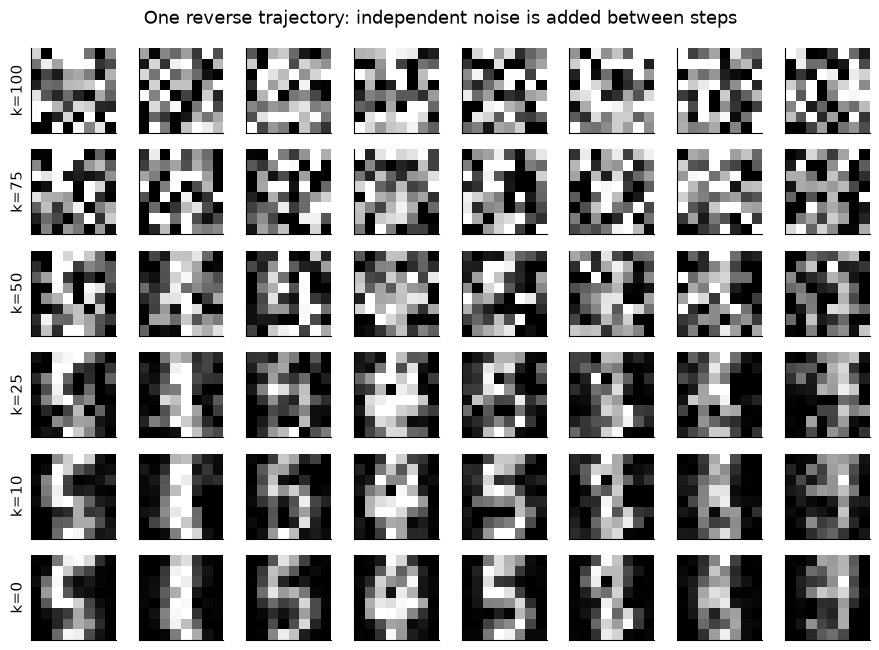

In [10]:
trace_steps = list(generation_trace)
fig, axes = plt.subplots(len(trace_steps), 8, figsize=(9, 1.1 * len(trace_steps)))
for row, k in enumerate(trace_steps):
    for col in range(8):
        axes[row, col].imshow(generation_trace[k][col].cpu().reshape(8, 8), cmap="gray", vmin=-1, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(f"k={k}")
fig.suptitle("One reverse trajectory: independent noise is added between steps")
plt.tight_layout()
plt.show()

- **Анализ генерации:** распознаваемость цифр, повторения, смешение классов. Одна решётка не подтверждает покрытие распределения.
- **Дополнительный эксперимент:** заменить `eps_pred` на `torch.zeros_like(x_t)`; сравнить при одинаковом seed.

<details><summary>Пояснение</summary>

Расписание задаёт уровни шума; структуру данных представляют обученные веса.
</details>

Удаление случайной добавки или пропуск итераций меняет сэмплер; такая модификация сама по себе не реализует DDIM.

## 7. Image-to-image: редактирование через зашумление

- **Метод:** зашумление входа до уровня $k$ → обратный DDPM; учебный вариант [SDEdit](https://arxiv.org/abs/2108.01073).
- **Данные:** test-цифры с искусственной полосой; оригинал доступен для вычисления MSE.
- **Эксперимент, 20 минут:** сравнить `EDIT_LEVELS`, изменить один уровень, повторить ячейку. Переобучение не требуется; seed сбрасывается.
- **Анализ:** сохранение штрихов и класса относительно степени изменения изображения.
- **Ограничение:** генеративный prior допускает изменение класса; точное условное восстановление не гарантируется.

Теория: [Редактирование с помощью диффузии](https://fpakhurov.com/ru/notes/generative-models/latent-diffusion/#editing-with-the-same-model), [DragGAN и DragDiffusion](https://fpakhurov.com/ru/notes/generative-models/drag-editing/).

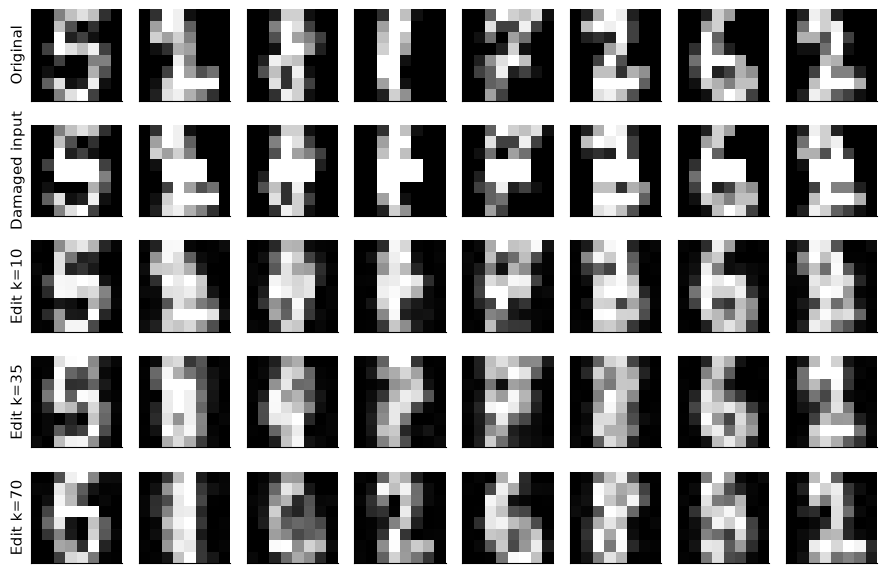

Pixel MSE to original in [-1, 1], damaged: 0.2009
Pixel MSE after editing: {10: 0.17, 35: 0.2114, 70: 0.3861}


In [11]:
torch.manual_seed(SEED + 7)
clean_edit = x_test[:8].clone()
damaged_edit = clean_edit.reshape(-1, 8, 8).clone()
damaged_edit[:, 3:5, 2:6] = 1.0
damaged_edit = damaged_edit.reshape(-1, 64)
edit_noise = torch.randn_like(damaged_edit)
edit_results = {}
EDIT_LEVELS = [10, 35, 70]
for k in EDIT_LEVELS:
    t = torch.full((len(damaged_edit),), k - 1, dtype=torch.long, device=device)
    initial = q_sample(damaged_edit, t, edit_noise)
    edited, _ = sample_ddpm(initial=initial, start_t=k - 1)
    edit_results[k] = edited

rows = [("Original", clean_edit), ("Damaged input", damaged_edit)] + [(f"Edit k={k}", result) for k, result in edit_results.items()]
fig, axes = plt.subplots(len(rows), 8, figsize=(9, 6))
for row, (label, images) in enumerate(rows):
    for col in range(8):
        axes[row, col].imshow(images[col].cpu().reshape(8, 8), cmap="gray", vmin=-1, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(label)
plt.tight_layout()
plt.show()
damaged_mse = F.mse_loss(damaged_edit, clean_edit).item()
edit_mse = {k: F.mse_loss(result, clean_edit).item() for k, result in edit_results.items()}
print("Pixel MSE to original in [-1, 1], damaged:", round(damaged_mse, 4))
print("Pixel MSE after editing:", {k: round(v, 4) for k, v in edit_mse.items()})

- **Масштаб MSE:** переход `[-1,1] → [0,1]` по формуле `(x+1)/2` уменьшает pixel MSE в 4 раза.
- MSE предсказания шума измеряет другую величину.
- Правдоподобное изменение класса может повышать MSE и нарушать требование сохранения содержания.

## 8. Дополнительно: заполнение пропусков

- **Маска:** $m=1$ на известных пикселях; $m=0$ в пропуске.
- **Проекция после обратного шага:**

$$x_{k-1}\leftarrow m\odot x_{k-1}^{known}+(1-m)\odot x_{k-1}^{generated}.$$

- Известная область зашумляется до соответствующего уровня; на финале возвращаются исходные пиксели.
- **Метрики:** сохранение известных пикселей; MSE только внутри пропуска относительно серого заполнения.
- **Ограничение:** эвристика; не точный conditional posterior и не полная схема RePaint.

Теория: [Score matching](https://fpakhurov.com/ru/notes/generative-models/score-matching/), [RePaint](https://arxiv.org/abs/2201.09865).

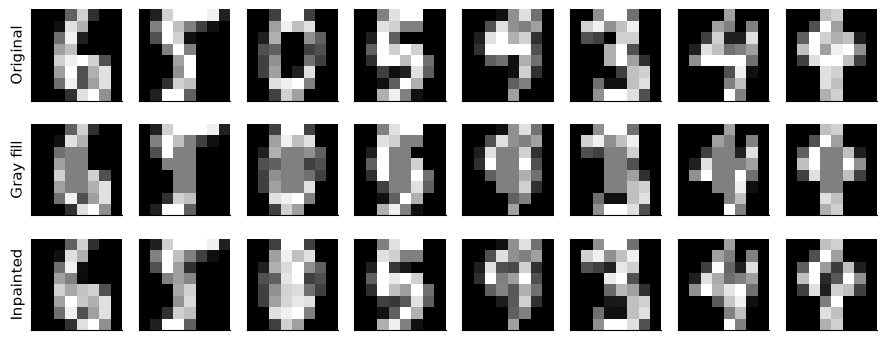

Known-pixel max error: 0.00e+00
Missing-pixel MSE, gray fill: 0.6499; inpainting: 0.6813


In [12]:
@torch.no_grad()
def inpaint(known_image, known_mask):
    current = torch.randn_like(known_image)
    known_noise = torch.randn_like(known_image)
    top_t = torch.full((len(current),), T - 1, dtype=torch.long, device=device)
    current = known_mask * q_sample(known_image, top_t, known_noise) + (1 - known_mask) * current
    for step_t in range(T - 1, -1, -1):
        t = torch.full((len(current),), step_t, dtype=torch.long, device=device)
        current = reverse_step(current, t)
        if step_t > 0:
            previous_t = torch.full((len(current),), step_t - 1, dtype=torch.long, device=device)
            known_at_level = q_sample(known_image, previous_t, known_noise)
        else:
            known_at_level = known_image
        current = known_mask * known_at_level + (1 - known_mask) * current
    return current

inpaint_original = x_test[8:16].clone()
known_mask = torch.ones_like(inpaint_original).reshape(-1, 8, 8)
known_mask[:, 2:6, 3:5] = 0.0
known_mask = known_mask.reshape(-1, 64)
inpaint_input = known_mask * inpaint_original
inpaint_result = inpaint(inpaint_original, known_mask)
known_pixel_error = ((inpaint_result - inpaint_original) * known_mask).abs().max().item()
assert known_pixel_error < 1e-6, known_pixel_error
missing_mask = 1 - known_mask
inpaint_missing_mse = (((inpaint_result - inpaint_original).square() * missing_mask).sum() / missing_mask.sum()).item()
gray_fill_missing_mse = (((inpaint_input - inpaint_original).square() * missing_mask).sum() / missing_mask.sum()).item()

fig, axes = plt.subplots(3, 8, figsize=(9, 3.7))
for row, (label, images) in enumerate([("Original", inpaint_original), ("Gray fill", inpaint_input), ("Inpainted", inpaint_result)]):
    for col in range(8):
        axes[row, col].imshow(images[col].cpu().reshape(8, 8), cmap="gray", vmin=-1, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(label)
plt.tight_layout()
plt.show()
print(f"Known-pixel max error: {known_pixel_error:.2e}")
print(f"Missing-pixel MSE, gray fill: {gray_fill_missing_mse:.4f}; inpainting: {inpaint_missing_mse:.4f}")

- **Дополнительный эксперимент:** увеличить пропуск; сравнить два результата с разными seeds.
- **Неоднозначность:** разные цифры могут совпадать на известных пикселях; правдоподобие не подтверждает восстановление оригинала.

## 9. Сравнение моделей

| Модель | Обучение | Генерация | Проверка |
|---|---|---|---|
| VAE | Восстановление + KL | Prior → decoder | Качество; согласованность prior/posterior |
| GAN | Состязательная оптимизация | Шум → генератор | Качество; разнообразие; коллапс мод |
| Поток | Точное правдоподобие | Обратимое преобразование | Test NLL; logdet; обратимость |
| Диффузия | Предсказание шума | Последовательность переходов | Качество; разнообразие; стоимость генерации |

- Точность вычисления плотности потока относится к модели, а не к истинному распределению.
- DDPM использует стохастический приближённый обратный процесс; обычный сэмплер не является обратимым потоком.
- Выбор downstream-метода зависит от условий: класс, парные изображения, непарные домены, частичные наблюдения.

**Контрольные вопросы:** назначение logdet; роль сети при известном начальном $x_T$; неоднозначность восстановления.

<details><summary>Ответы</summary>

- Logdet учитывает изменение объёма.
- $x_T$ известен, но исходная чистая цифра не задана. Сеть задаёт обратные переходы, согласованные с данными.
- Наблюдаемый фрагмент допускает несколько продолжений; одно изображение не устанавливает истинный оригинал.
</details>

In [13]:
SEMINAR_RESULTS = {
    "quick_mode": QUICK,
    "device": str(device),
    "flow_steps": FLOW_STEPS,
    "ddpm_steps": DDPM_STEPS,
    "gaussian_test_nll": gaussian_nll,
    "flow_test_nll": flow_nll,
    "flow_roundtrip_max_error": roundtrip_error,
    "flow_jacobian_logdet_error": jacobian_logdet_error,
    "ddpm_test_noise_mse": test_noise_mse,
    "ddpm_zero_predictor_mse": zero_noise_mse,
    "oracle_x0_max_error": oracle_x0_error,
    "damaged_edit_mse": damaged_mse,
    "edit_mse_by_start_k": edit_mse,
    "inpaint_known_pixel_max_error": known_pixel_error,
    "inpaint_missing_mse": inpaint_missing_mse,
    "gray_fill_missing_mse": gray_fill_missing_mse,
    "flow_seconds": flow_seconds,
    "ddpm_seconds": ddpm_seconds,
}
print(SEMINAR_RESULTS)

{'quick_mode': False, 'device': 'cpu', 'flow_steps': 1600, 'ddpm_steps': 16000, 'gaussian_test_nll': 2.718989372253418, 'flow_test_nll': 1.5947524309158325, 'flow_roundtrip_max_error': 7.152557373046875e-07, 'flow_jacobian_logdet_error': 1.6689300537109375e-06, 'ddpm_test_noise_mse': 0.20697709918022156, 'ddpm_zero_predictor_mse': 0.9933120608329773, 'oracle_x0_max_error': 0.00011539459228515625, 'damaged_edit_mse': 0.20086669921875, 'edit_mse_by_start_k': {10: 0.17002394795417786, 35: 0.21135960519313812, 70: 0.3861265778541565}, 'inpaint_known_pixel_max_error': 0.0, 'inpaint_missing_mse': 0.6812981963157654, 'gray_fill_missing_mse': 0.64990234375, 'flow_seconds': 5.469806459033862, 'ddpm_seconds': 24.339936541975476}


## Первоисточники и материалы курса

- [HSE-LAMBDA: Deep Generative Models](https://github.com/HSE-LAMBDA/DeepGenerativeModels/tree/spring-2025-long).
- [Real NVP](https://arxiv.org/abs/1605.08803): обратимые coupling-преобразования.
- [DDPM](https://arxiv.org/abs/2006.11239): прямой процесс, posterior, обучение.
- [SDEdit](https://arxiv.org/abs/2108.01073): редактирование через шум.
- [RePaint](https://arxiv.org/abs/2201.09865): диффузионный inpainting.
- [load_digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html): источник данных.

Реализации самостоятельные; тематические ссылки на подробную теорию приведены в соответствующих разделах.